# Assignment Problems: Day 12
The following problems require access to the file named ‘Dataset_Day12.csv’, provided with this assignment. 

This is the same assignment data as Day 11.

The datasets include data from 768 women with several medical predictor variables and one target variable(‘Outcome’). The classification goal is to predict whether or not the patients in the dataset have diabetes or not.
 
For columns: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction

If the column value is 0, then they should be considered as missing data.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn import tree
from math import log, sqrt
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score, KFold 
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import AdaBoostClassifier

* Firstly, replace all Missing values with relevant figures.
* Then remove all existing outliers and get the final data for classification.

In [3]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame(columns = ["Pregnancies","Glucose","BloodPressure","BMI","Age"])
temp = data.drop('Outcome',axis=1)
for col in ["Pregnancies","Glucose","BloodPressure","BMI","Age"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    outlier[col] = temp[col][(temp[col]<=LowerBound)|(temp[col]>=UpperBound)]

OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))

Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0


C:\Users\nikhi\AppData\Local\Temp\ipykernel_2736\3315839205.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()



no. of Outlier 4 
% of Outlier =  0.5208333333333333


* Split the data into 80% training and 20% testing data. Use target variable as ‘Outcome’.

In [4]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=4)

* Use Naïve Bayes Classifier algorithm to classify Outcome and print the default model performance metrics: Accuracy, Precision, Recall, F1Score.

Model Performance metrics are as below :-

Accuracy is  0.7777777777777778
Precision is  0.7435897435897436
Recall is  0.5471698113207547
F1-Score is  0.6304347826086957
[[90 10]
 [24 29]]


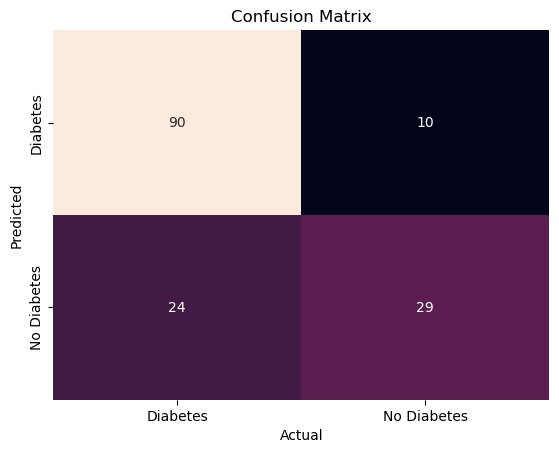

In [5]:
model = GaussianNB()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()

* Use k-Fold Cross Validation to find the best model performance metrics .

In [10]:
kf = KFold(n_splits=5)
result = cross_val_score(model , X, y, scoring = "f1" , cv = kf)
print(result)
print("Avg f1 score : ", result.mean())

[0.64       0.60176991 0.62626263 0.68235294 0.66037736]
Avg f1 score :  0.6421525674868176


* Try out Adaboost algorithm for Naïve Bayes Classifier improvement. [Optional]

In [7]:
abc = AdaBoostClassifier(n_estimators=67, estimator=model, learning_rate = 1)
abc.fit(X_train, y_train)
y_pred = abc.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is ",accuracy_score(y_test,y_pred))
print("Precision is ",precision_score(y_test,y_pred))
print("Recall is ",recall_score(y_test,y_pred))
print("F1-Score is ",f1_score(y_test,y_pred))

Model Performance metrics are as below :-

Accuracy is  0.7320261437908496
Precision is  0.5789473684210527
Recall is  0.8301886792452831
F1-Score is  0.682170542635659


In [8]:
kf = KFold(n_splits=5)
result = cross_val_score(abc , X, y, scoring = "f1" , cv = kf)
print(result)
print("Avg f1 score : ", result.mean())

[0.47272727 0.56216216 0.13333333 0.4109589  0.54644809]
Avg f1 score :  0.4251259519528102


In [9]:
x = pd.read_csv("classification.csv")
x

,model,accuracy,precision,recall,f1-score
0,Simple Logistic Regression,0.725225,0.544000,0.944444,0.690355
1,k Neighbour (manhattan),0.847826,0.879310,0.645570,0.744526
2,SVM,0.648649,0.727273,0.767196,0.685714
3,Dicision Tree Classifier,0.836601,0.759259,0.773585,0.766355
4,Bagging Classifier,0.830065,0.764706,0.735849,0.750000
5,Random Forest Classifier,0.797386,0.739130,0.641509,0.686869
6,Ada Boost Classifier,0.830065,0.829268,0.641509,0.723404
7,Gaussian NB,0.777778,0.743590,0.547170,0.630435


Name - Nikhil Khatri

SIC - 21BCSA92